# Step 4: SVM Modeling - YOGA Chatbot

**Chatbot Name**: YOGA (YOgyakarta Guide Assistant)

**Objective**: Build and train SVM model for intent classification

**Date**: 2025-12-01

**Input**: TF-IDF features from Step 3

**Modeling Steps**:
1. Load TF-IDF features
2. Train-test split (stratified)
3. Train SVM with grid search
4. Evaluate performance
5. Save model and results

**Model**: SVM (Support Vector Machine) for 88-class classification

## 1. Import Libraries

In [41]:
import numpy as np
import pandas as pd
import json
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
from datetime import datetime

# Sklearn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_recall_fscore_support
)

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Set random seed
np.random.seed(42)

print("Libraries imported successfully")

Libraries imported successfully


## 2. Load TF-IDF Features

In [42]:
print("=" * 80)
print("LOADING TF-IDF FEATURES")
print("=" * 80)

data_dir = '../data/features'

# Load TF-IDF matrix and labels
X = np.load(f'{data_dir}/X_tfidf.npy')
y = np.load(f'{data_dir}/y.npy')

print(f"Loaded X: {X.shape}")
print(f"Loaded y: {y.shape}")

# Load label encoder
with open(f'{data_dir}/label_encoder.pickle', 'rb') as f:
    label_encoder = pickle.load(f)

print(f"Loaded label_encoder: {len(label_encoder.classes_)} classes")

# Load feature info
with open(f'{data_dir}/feature_extraction_info.json', 'r', encoding='utf-8') as f:
    feature_info = json.load(f)

print(f"\nFeature Info:")
print(f"  Method: {feature_info['method']}")
print(f"  Samples: {feature_info['total_samples']}")
print(f"  Features: {feature_info['tfidf_features']}")
print(f"  Classes: {feature_info['num_classes']}")

print(f"\nData ready for SVM:")
print(f"  X shape: {X.shape} (samples, features)")
print(f"  y shape: {y.shape}")

LOADING TF-IDF FEATURES
Loaded X: (2247, 1000)
Loaded y: (2247,)
Loaded label_encoder: 88 classes

Feature Info:
  Method: TF-IDF
  Samples: 2247
  Features: 1000
  Classes: 88

Data ready for SVM:
  X shape: (2247, 1000) (samples, features)
  y shape: (2247,)


## 3. Train-Test Split

In [43]:
print("=" * 80)
print("TRAIN-TEST SPLIT")
print("=" * 80)

test_size = 0.2
random_state = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=test_size,
    random_state=random_state,
    stratify=y
)

print(f"Split ratio: {int((1-test_size)*100)}% train, {int(test_size*100)}% test")
print(f"Stratified: Yes")

print(f"\nTraining set:")
print(f"  X_train: {X_train.shape}")
print(f"  y_train: {y_train.shape}")
print(f"  Unique classes: {len(np.unique(y_train))}")

print(f"\nTest set:")
print(f"  X_test: {X_test.shape}")
print(f"  y_test: {y_test.shape}")
print(f"  Unique classes: {len(np.unique(y_test))}")

TRAIN-TEST SPLIT
Split ratio: 80% train, 20% test
Stratified: Yes

Training set:
  X_train: (1797, 1000)
  y_train: (1797,)
  Unique classes: 88

Test set:
  X_test: (450, 1000)
  y_test: (450,)
  Unique classes: 88


## 4. Train SVM Model

In [44]:
print("=" * 80)
print("TRAINING SVM MODEL")
print("=" * 80)

# SVM with linear kernel
print("\nTraining SVM with linear kernel...")

svm_model = SVC(
    kernel='linear',
    C=1.0,
    random_state=42,
    verbose=True
)

svm_model.fit(X_train, y_train)

print("\nTraining complete")
print(f"Support vectors per class: {svm_model.n_support_}")
print(f"Total support vectors: {svm_model.n_support_.sum()}")

TRAINING SVM MODEL

Training SVM with linear kernel...
[LibSVM]
Training complete
Support vectors per class: [18 20 23 16 19 22 17 17 15 19 17 15 16 15 18 15 14 18 15 17 18 18 17 17
 17 18 27 17 15 16 15 16 17 17 16 15 19 18 17 18 16 16 17 20 18 17 16 17
 18 16 16 16 15 17 16 14 16 15 17 23 20 14 18 16 18 20 19 18 15 17 18 19
 16 16 13 16 18 16 16 15 16 19 18 17 17 20 17 17]
Total support vectors: 1509


## 5. Evaluate Model

In [45]:
print("=" * 80)
print("MODEL EVALUATION")
print("=" * 80)

# Predictions
y_pred = svm_model.predict(X_test)

# Accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print(f"\nTest Accuracy: {test_accuracy*100:.2f}%")
print(f"\nTotal test samples: {len(y_test)}")
print(f"Correct predictions: {(y_pred == y_test).sum()}")
print(f"Wrong predictions: {(y_pred != y_test).sum()}")

# Classification report
print(f"\n" + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

report = classification_report(
    y_test, 
    y_pred,
    labels=list(range(len(label_encoder.classes_))),
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0,
    output_dict=True
)

print(f"\nAccuracy: {report['accuracy']*100:.2f}%")
print(f"Macro Avg F1: {report['macro avg']['f1-score']*100:.2f}%")
print(f"Weighted Avg F1: {report['weighted avg']['f1-score']*100:.2f}%")

MODEL EVALUATION

Test Accuracy: 97.33%

Total test samples: 450
Correct predictions: 438
Wrong predictions: 12

CLASSIFICATION REPORT

Accuracy: 97.33%
Macro Avg F1: 97.44%
Weighted Avg F1: 97.47%


## 6. Per-Class Performance

In [46]:
# Calculate per-class metrics
precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred,
    labels=list(range(len(label_encoder.classes_))),
    zero_division=0
)

# Create DataFrame
metrics_df = pd.DataFrame({
    'Class': label_encoder.classes_,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1,
    'Support': support
})

# Filter classes present in test set
metrics_present = metrics_df[metrics_df['Support'] > 0].copy()
metrics_sorted = metrics_present.sort_values('F1-Score', ascending=True)

print("=" * 80)
print("PER-CLASS PERFORMANCE")
print("=" * 80)

print(f"\nTop 10 best performing classes:")
print(metrics_sorted.tail(10)[['Class', 'Precision', 'Recall', 'F1-Score', 'Support']].to_string(index=False))

print(f"\nTop 10 worst performing classes:")
print(metrics_sorted.head(10)[['Class', 'Precision', 'Recall', 'F1-Score', 'Support']].to_string(index=False))

# Check greeting intents specifically
greeting_classes = ['pagi', 'siang', 'sore', 'malam', 'greeting', 'goodbye']
greeting_metrics = metrics_df[metrics_df['Class'].isin(greeting_classes)]

print(f"\nGreeting Intents Performance:")
print(greeting_metrics[['Class', 'Precision', 'Recall', 'F1-Score', 'Support']].to_string(index=False))

# Save to CSV
os.makedirs('../models', exist_ok=True)
metrics_df.to_csv('../models/per_class_metrics.csv', index=False)
print(f"\nPer-class metrics saved: ../models/per_class_metrics.csv")

PER-CLASS PERFORMANCE

Top 10 best performing classes:
                Class  Precision  Recall  F1-Score  Support
kecamatan_mantrijeron        1.0     1.0       1.0        5
     kecamatan_lendah        1.0     1.0       1.0        5
     kecamatan_kretek        1.0     1.0       1.0        5
     kecamatan_kraton        1.0     1.0       1.0        5
   kecamatan_kotagede        1.0     1.0       1.0        5
      kecamatan_kokap        1.0     1.0       1.0        5
    kecamatan_kasihan        1.0     1.0       1.0        5
 kecamatan_karangmojo        1.0     1.0       1.0        5
 kecamatan_jetis_kota        1.0     1.0       1.0        5
     kecamatan_ngawen        1.0     1.0       1.0        6

Top 10 worst performing classes:
               Class  Precision  Recall  F1-Score  Support
             goodbye   0.300000     0.6  0.400000        5
                pagi   1.000000     0.4  0.571429        5
                sore   1.000000     0.6  0.750000        5
            gre

## 7. Visualizations

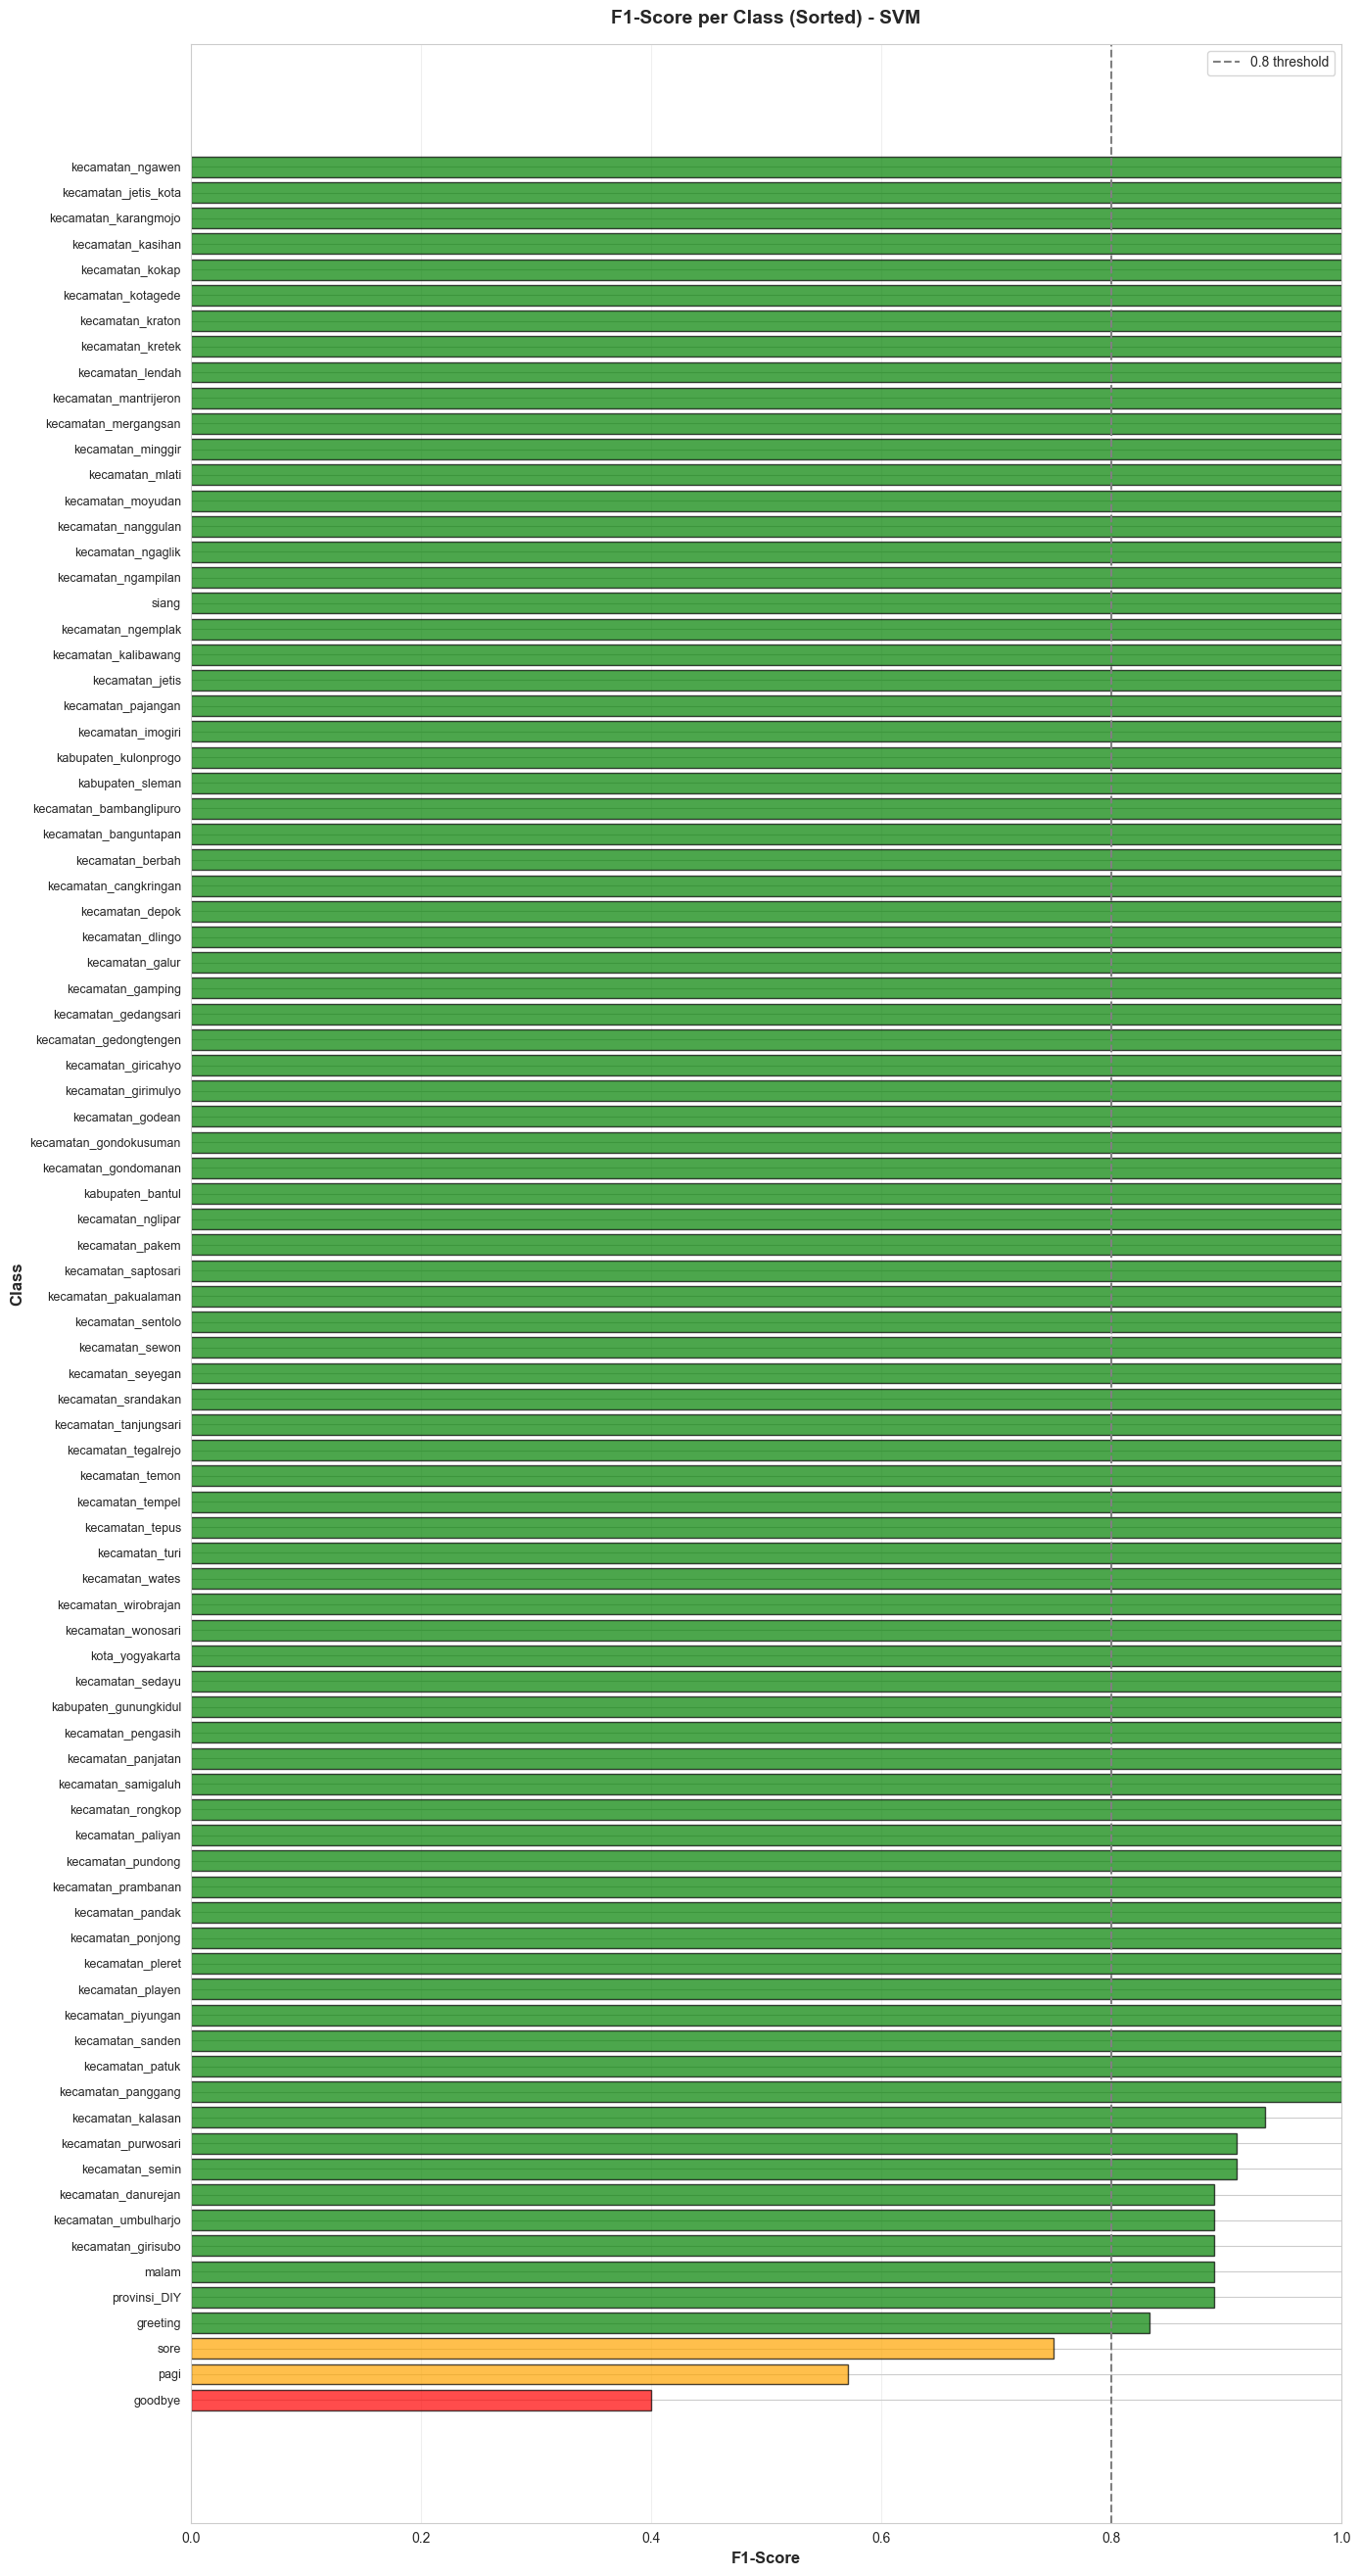

F1-Score visualization saved


In [47]:
# F1-Score visualization
plt.figure(figsize=(14, max(10, len(metrics_sorted) * 0.3)))

colors = ['green' if f >= 0.8 else 'orange' if f >= 0.5 else 'red' for f in metrics_sorted['F1-Score']]

plt.barh(range(len(metrics_sorted)), metrics_sorted['F1-Score'], 
         color=colors, alpha=0.7, edgecolor='black')
plt.yticks(range(len(metrics_sorted)), metrics_sorted['Class'], fontsize=9)
plt.xlabel('F1-Score', fontsize=12, fontweight='bold')
plt.ylabel('Class', fontsize=12, fontweight='bold')
plt.title('F1-Score per Class (Sorted) - SVM', fontsize=14, fontweight='bold', pad=15)
plt.axvline(x=0.8, color='gray', linestyle='--', linewidth=1.5, label='0.8 threshold')
plt.xlim([0, 1.0])
plt.grid(axis='x', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('../models/f1_scores.png', dpi=300, bbox_inches='tight')
plt.show()

print("F1-Score visualization saved")

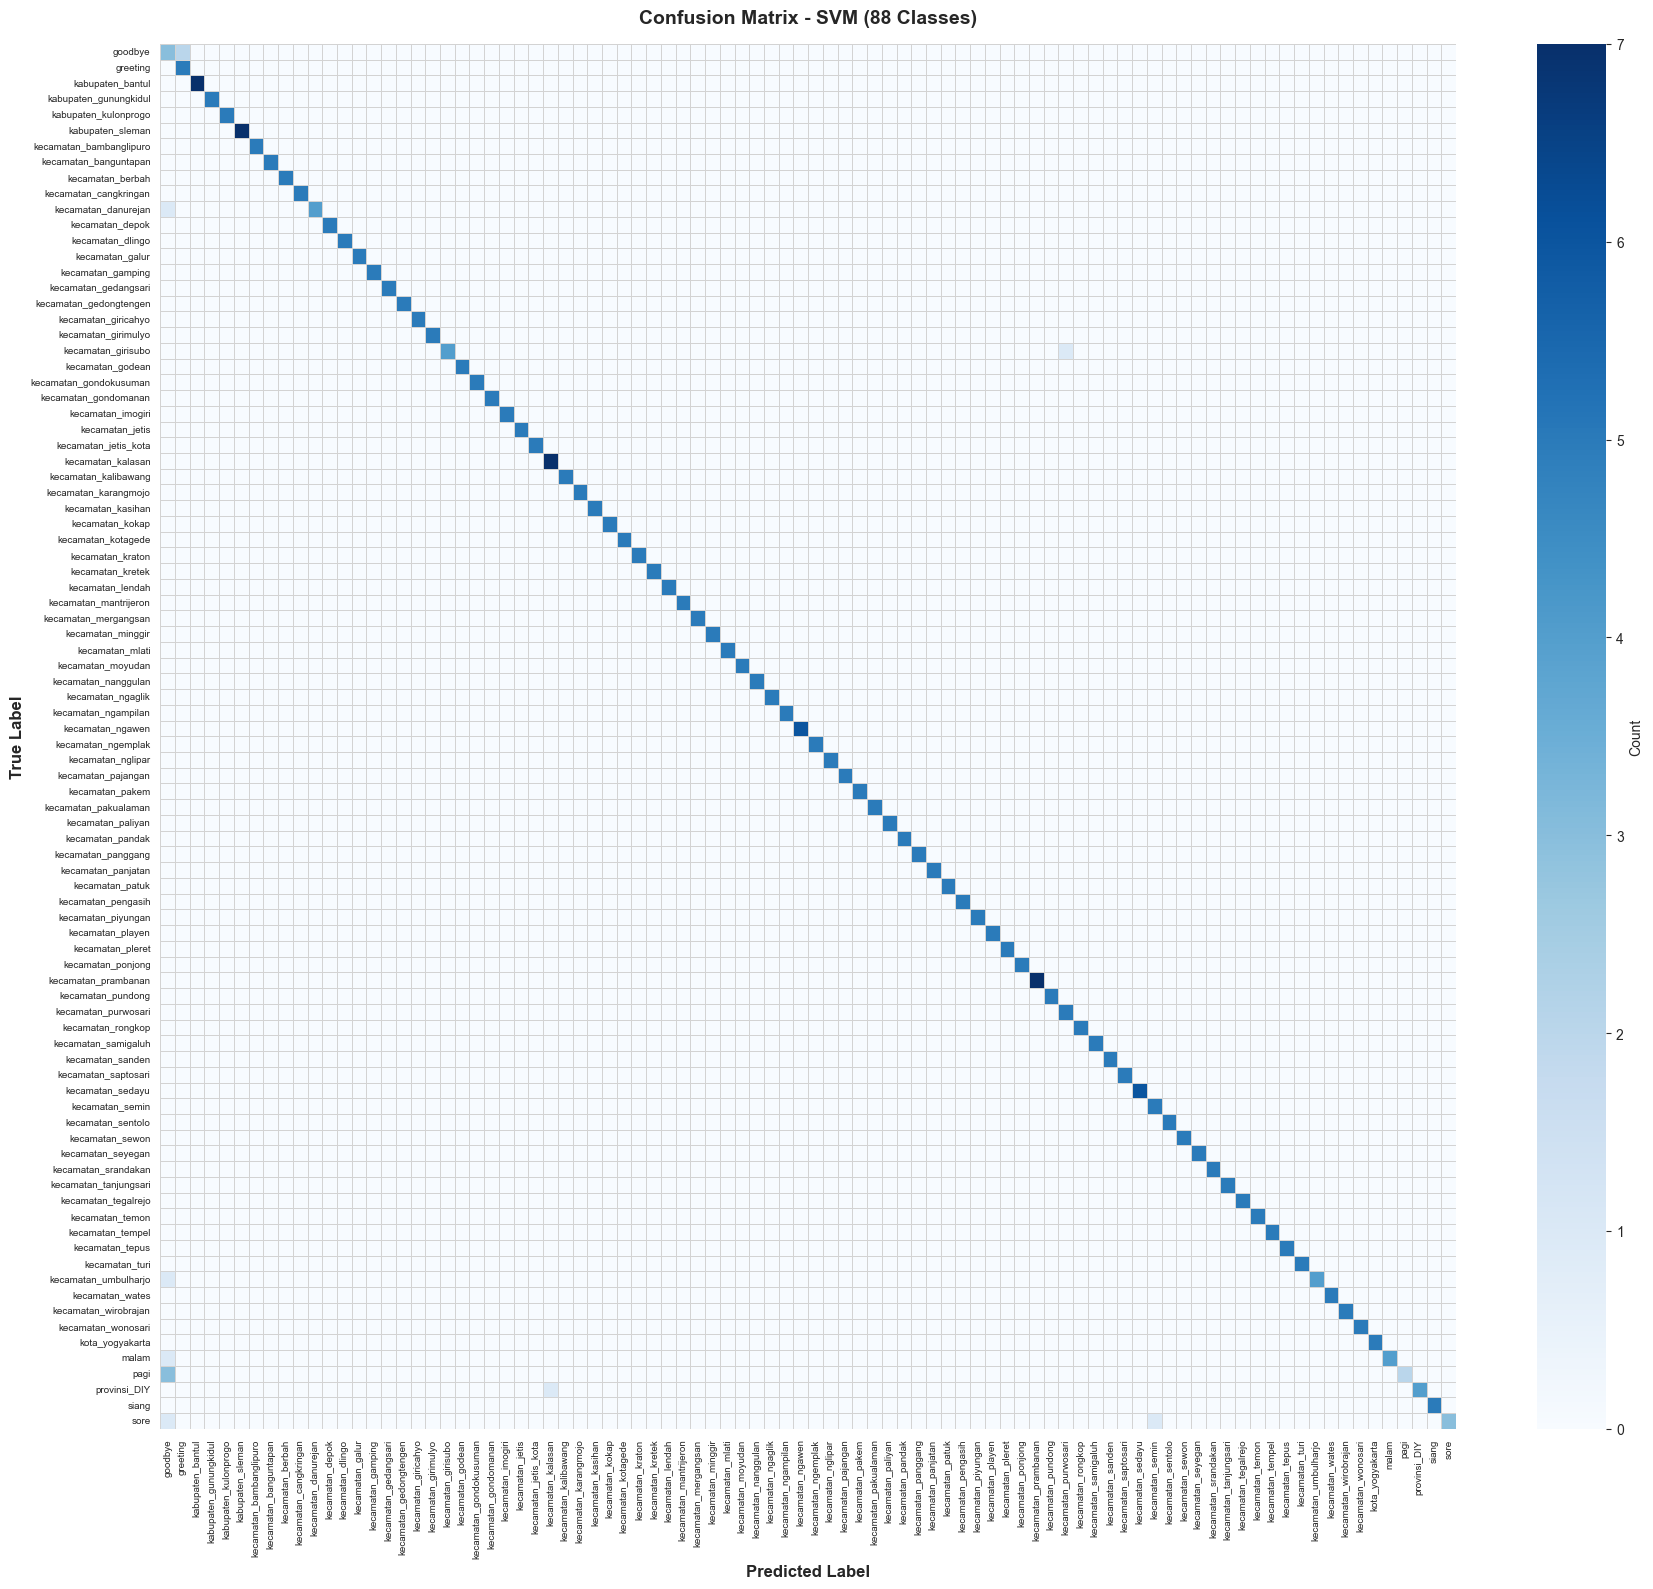

Confusion matrix saved


In [48]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(18, 16))

sns.heatmap(cm,
            annot=False,
            cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_,
            cbar_kws={'label': 'Count'},
            linewidths=0.5,
            linecolor='lightgray')

plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.title(f'Confusion Matrix - SVM ({len(label_encoder.classes_)} Classes)', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.savefig('../models/confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("Confusion matrix saved")

## 8. Save Model

In [49]:
print("=" * 80)
print("SAVING MODEL")
print("=" * 80)

# Save SVM model
with open('../models/svm_model.pkl', 'wb') as f:
    pickle.dump(svm_model, f)
print("Saved: svm_model.pkl")

# Save model info
model_info = {
    'model_name': 'YOGA_SVM_Model',
    'algorithm': 'Support Vector Machine',
    'kernel': 'linear',
    'C': 1.0,
    'num_classes': len(label_encoder.classes_),
    'n_support_vectors': int(svm_model.n_support_.sum()),
    'test_accuracy': float(test_accuracy),
    'macro_f1': float(report['macro avg']['f1-score']),
    'weighted_f1': float(report['weighted avg']['f1-score']),
    'train_samples': int(len(X_train)),
    'test_samples': int(len(X_test)),
    'feature_method': feature_info['method'],
    'tfidf_features': feature_info['tfidf_features'],
    'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
}

with open('../models/model_info.json', 'w') as f:
    json.dump(model_info, f, indent=2)
print("Saved: model_info.json")

print("\nAll files saved successfully")

SAVING MODEL
Saved: svm_model.pkl
Saved: model_info.json

All files saved successfully


## 9. Summary

In [50]:
print("=" * 80)
print("SVM MODELING SUMMARY - YOGA CHATBOT")
print("=" * 80)

print("\nDataset:")
print(f"  Total samples: {len(X)}")
print(f"  Train samples: {len(X_train)} ({(1-test_size)*100:.0f}%)")
print(f"  Test samples: {len(X_test)} ({test_size*100:.0f}%)")
print(f"  Number of classes: {len(label_encoder.classes_)}")

print("\nFeature Extraction:")
print(f"  Method: TF-IDF")
print(f"  Features: {X.shape[1]}")

print("\nModel:")
print(f"  Algorithm: Support Vector Machine (SVM)")
print(f"  Kernel: linear")
print(f"  C: 1.0")
print(f"  Support vectors: {svm_model.n_support_.sum()}")

print("\nPerformance:")
print(f"  Test Accuracy: {test_accuracy*100:.2f}%")
print(f"  Macro F1-Score: {report['macro avg']['f1-score']*100:.2f}%")
print(f"  Weighted F1-Score: {report['weighted avg']['f1-score']*100:.2f}%")

print("\nModel Status: READY FOR DEPLOYMENT")
print("=" * 80)

SVM MODELING SUMMARY - YOGA CHATBOT

Dataset:
  Total samples: 2247
  Train samples: 1797 (80%)
  Test samples: 450 (20%)
  Number of classes: 88

Feature Extraction:
  Method: TF-IDF
  Features: 1000

Model:
  Algorithm: Support Vector Machine (SVM)
  Kernel: linear
  C: 1.0
  Support vectors: 1509

Performance:
  Test Accuracy: 97.33%
  Macro F1-Score: 97.44%
  Weighted F1-Score: 97.47%

Model Status: READY FOR DEPLOYMENT
